# LU vs QR: what happens to angles?

Every 2×2 matrix `A` moves the plane: it takes the two basis arrows `e1 = (1,0)` and `e2 = (0,1)` (which meet at 90°) and sends them somewhere else.

Decomposing `A` splits that one move into two simpler moves. This notebook factors a 2×2 matrix in two ways and watches what each factor does to the angle between the two arrows:

- **LU**: `A = L U`, built by Gaussian elimination
- **QR**: `A = Q R`, built by Gram–Schmidt

The punchline: the `L` from LU **changes** the angle, while the `Q` from QR **never does**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

A = np.array([[4.0, 2.0],
              [1.0, 3.0]])

print("A =")
print(A)
print("det(A) =", round(np.linalg.det(A), 3))

A =
[[4. 2.]
 [1. 3.]]
det(A) = 10.0


## LU: record the elimination

To clear the `1` below the top-left `4`, subtract `1/4` of row 1 from row 2. That leaves an upper triangular matrix `U`, and the multiplier `1/4` is stored in `L` so nothing is lost.

Each such step is a **shear**: it slides one direction sideways in proportion to another.

In [2]:
def lu_decomposition(A):
    n = A.shape[0]
    U = A.astype(float).copy()
    L = np.eye(n)
    for col in range(n):
        pivot = U[col, col]
        assert abs(pivot) > 1e-12, "Zero pivot: this simple version does not swap rows."
        for row in range(col + 1, n):
            factor = U[row, col] / pivot        # the multiplier
            L[row, col] = factor                # store it in L
            U[row, :] -= factor * U[col, :]     # eliminate the entry
    return L, U

L, U = lu_decomposition(A)

print("L ="); print(L)
print("U ="); print(U)
assert np.allclose(L @ U, A)
print("\nCheck: L @ U equals A")

L =
[[1.   0.  ]
 [0.25 1.  ]]
U =
[[4.  2. ]
 [0.  2.5]]

Check: L @ U equals A


## QR: peel off what is already covered

Take the columns of `A` one at a time. Keep the first direction as it is (just scaled to length 1). For the second column, subtract the part that lies along the first direction, and scale what remains to length 1. The two resulting unit vectors, at right angles, are the columns of `Q`; `R` records what was subtracted and the lengths.

In [3]:
def qr_decomposition(A):
    n, m = A.shape
    Q = np.zeros((n, m))
    R = np.zeros((m, m))
    for j in range(m):
        v = A[:, j].astype(float).copy()
        for i in range(j):
            R[i, j] = Q[:, i] @ A[:, j]     # how much of q_i is in this column
            v -= R[i, j] * Q[:, i]          # remove it
        R[j, j] = np.linalg.norm(v)         # what is left
        Q[:, j] = v / R[j, j]               # make it unit length
    return Q, R

Q, R = qr_decomposition(A)

print("Q ="); print(Q)
print("R ="); print(R)
assert np.allclose(Q @ R, A)
assert np.allclose(Q.T @ Q, np.eye(2))
print("\nChecks: Q @ R equals A, and Q.T @ Q is the identity")

Q =
[[ 0.97  -0.243]
 [ 0.243  0.97 ]]
R =
[[4.123 2.668]
 [0.    2.425]]

Checks: Q @ R equals A, and Q.T @ Q is the identity


## The test: push the unit square through each factor

The unit square is spanned by `e1` and `e2`, which meet at 90°. We apply a factor to both arrows and look at the shape they now span and the angle between them. The dashed outline is the original square.

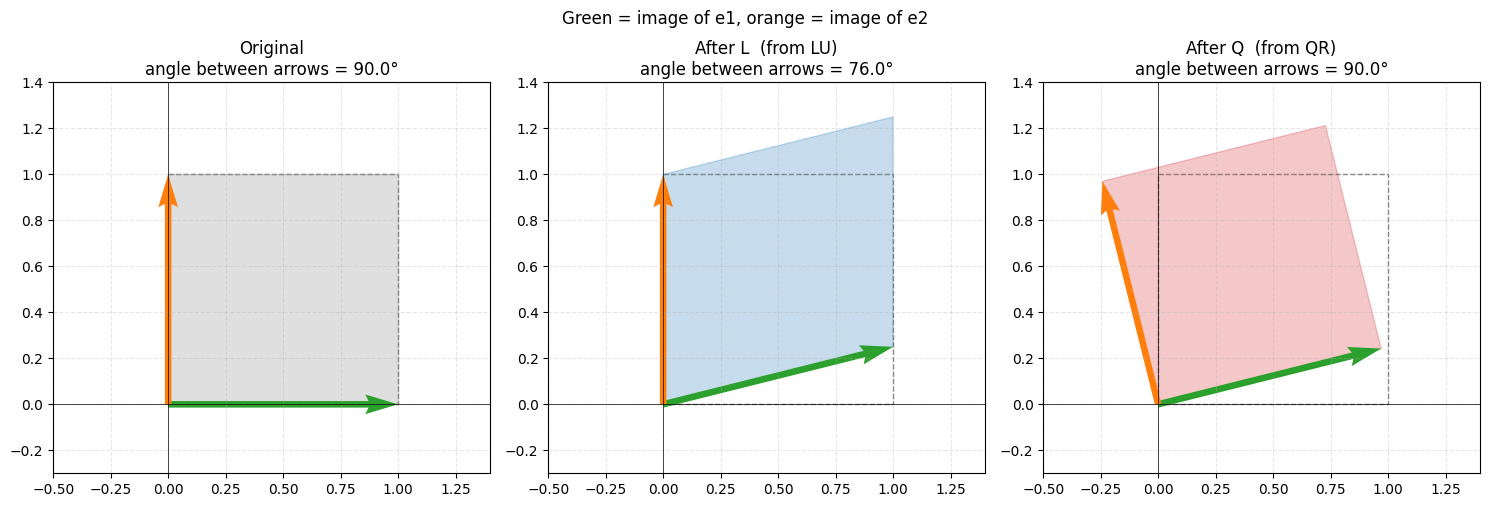

In [4]:
def angle_between(v1, v2):
    c = v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

square = np.array([[0, 1, 1, 0],
                   [0, 0, 1, 1]], dtype=float)      # corners (0,0) (1,0) (1,1) (0,1)

panels = [("Original", np.eye(2), "gray"),
          ("After L  (from LU)", L, "tab:blue"),
          ("After Q  (from QR)", Q, "tab:red")]


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, M, color) in zip(axes, panels):
    out = M @ square
    ax.fill(*square, fill=False, ls="--", ec="gray")            # original square
    ax.fill(*out, alpha=0.25, color=color)                      # transformed shape
    for k, c in enumerate(["tab:green", "tab:orange"]):
        ax.quiver(0, 0, M[0, k], M[1, k], angles="xy", scale_units="xy", scale=1,
                  color=c, width=0.015)
    ang = angle_between(M[:, 0], M[:, 1])
    ax.set_title(f"{title}\nangle between arrows = {ang:.1f}°")
    ax.set_xlim(-0.5, 1.4); ax.set_ylim(-0.3, 1.4)
    ax.set_aspect("equal"); ax.grid(alpha=0.3, ls="--")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)

plt.suptitle("Green = image of e1, orange = image of e2", y=1.0)
plt.tight_layout()
plt.savefig("images/angles_L_vs_Q.png", dpi=130, bbox_inches="tight")
plt.show()

`L` slides the square into a **parallelogram**: the arrows lean toward each other and the right angle is gone. `Q` just **rotates** the square: same shape, same angle.

In [5]:
print("Angle between the images of e1 and e2 (originally 90°):\n")
for name, M in [("L", L), ("U", U), ("Q", Q), ("R", R)]:
    print(f"  {name}: {angle_between(M[:, 0], M[:, 1]):6.2f}°")

Angle between the images of e1 and e2 (originally 90°):

  L:  75.96°
  U:  51.34°
  Q:  90.00°
  R:  42.27°


**What this shows**

- `Q` keeps the angle at exactly 90°, because its columns are orthonormal: it only rotates (or reflects).
- `L` changes it, and so does `U`. LU splits `A` into **two** factors that both distort space.
- `R` changes it too. In QR all the distortion is gathered into `R`, and `Q` is a pure rotation, so no rotation is "hidden" in a distorting factor.